# Phase 3: Feature Engineering & Noise Reduction — IPS (Relative RSSI-Based)

Melanjutkan output Phase 2 (`ips_dataset_wide_windowed.csv`: `Table, Side, RSSI_3, RSSI_8, RSSI_33, RSSI_38`). Notebook ini mengerjakan:

- **Feature 1** — Kalman Filter: menghaluskan RSSI per beacon per titik sepanjang urutan pembacaan.
- **Feature 2** — Beacon RSSI Reranking: urutan beacon dari sinyal terkuat ke terlemah (per baris).
- **Feature 3** — Pairwise Difference RSSI: selisih RSSI antar setiap pasangan beacon (adaptasi *LANDMARC into feature space*).
- **Normalization/Scaling** — standardisasi fitur akhir sebelum masuk ke model klasifikasi (Phase 4).

In [12]:
import os
from itertools import combinations

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
BEACONS = [3, 8, 33, 38]

## 0. Mount local directory & Load Output Phase 2

In [13]:
from google.colab import drive

PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), '..', 'Main_Data'))
FILENAME = 'ips_dataset_wide_windowed.csv'
# ================================================================

os.chdir(PROJECT_PATH)
df = pd.read_csv(FILENAME)
print(df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(16346, 12)


,Table,Side,Timestamp,RSSI_3,RSSI_8,RSSI_33,RSSI_38,Age_3,Age_8,Age_33,Age_38,Sample
0,1,1,2026-08-03 11:35:51.506,-56.0,-67.0,-69.0,-70.0,0.566,0.000,1.139,0.905,21
1,1,1,2026-08-03 11:35:51.646,-56.0,-67.0,-74.0,-70.0,0.706,0.140,0.000,1.045,22
2,1,1,2026-08-03 11:35:51.883,-56.0,-67.0,-74.0,-75.5,0.943,0.377,0.237,0.000,23
3,1,1,2026-08-03 11:35:52.226,-60.0,-67.0,-74.0,-75.5,0.000,0.720,0.580,0.343,24
4,1,1,2026-08-03 11:35:53.173,-60.0,-67.0,-74.0,-70.0,0.947,1.667,1.527,0.000,25


## Rekonstruksi Urutan Waktu per Titik

Kolom `Sample`/`Age` dari Phase 2 sudah tidak disimpan (tidak dibutuhkan untuk training). Kalman Filter butuh urutan waktu, jadi kita asumsikan **urutan baris di CSV = urutan kronologis asli** (belum pernah di-shuffle) dan pakai posisi baris di dalam tiap `(Table, Side)` sebagai pengganti index waktu.

> Kalau nanti CSV ini pernah di-`sample()`/di-shuffle/digabung ulang di luar pipeline ini, urutan ini jadi tidak valid — pastikan proses dari Phase 2 ke sini tidak mengacak baris.

In [14]:
beacon_cols = [f'RSSI_{b}' for b in BEACONS]

df = df.reset_index(drop=True)
df['Sample'] = df.groupby(['Table', 'Side']).cumcount()
df = df.sort_values(['Table', 'Side', 'Sample']).reset_index(drop=True)
df.head()

,Table,Side,Timestamp,RSSI_3,RSSI_8,RSSI_33,RSSI_38,Age_3,Age_8,Age_33,Age_38,Sample
0,1,1,2026-08-03 11:35:51.506,-56.0,-67.0,-69.0,-70.0,0.566,0.000,1.139,0.905,0
1,1,1,2026-08-03 11:35:51.646,-56.0,-67.0,-74.0,-70.0,0.706,0.140,0.000,1.045,1
2,1,1,2026-08-03 11:35:51.883,-56.0,-67.0,-74.0,-75.5,0.943,0.377,0.237,0.000,2
3,1,1,2026-08-03 11:35:52.226,-60.0,-67.0,-74.0,-75.5,0.000,0.720,0.580,0.343,3
4,1,1,2026-08-03 11:35:53.173,-60.0,-67.0,-74.0,-70.0,0.947,1.667,1.527,0.000,4


## Feature 1 — Kalman Filter

Kalman Filter 1D sederhana (model random-walk: sinyal RSSI 'sebenarnya' dianggap berubah pelan, pembacaan mentah dianggap versi noisy-nya). Untuk tiap beacon di tiap titik `(Table, Side)`, filter dijalankan berurutan sepanjang `Sample`:

- `Q` (process noise) — seberapa besar sinyal 'sebenarnya' boleh berubah antar pembacaan. Titik diam → kecil.
- `R` (measurement noise) — seberapa berisik sensor RSSI-nya. Makin besar `R`, makin agresif filter meredam fluktuasi.

Nilai default (`Q=0.05`, `R=4.0`) adalah titik awal — cek hasil plot di bawah, kalau garis KF masih terlalu bergerigi naikkan `R` atau turunkan `Q`; kalau terlalu lambat mengikuti sinyal, sebaliknya.

In [15]:
def kalman_filter_1d(series, Q=0.05, R=4.0):
    z = series.to_numpy(dtype=float)
    n = len(z)
    x = np.zeros(n)
    P = np.zeros(n)
    x[0] = z[0]
    P[0] = 1.0
    for t in range(1, n):
        x_pred = x[t - 1]
        P_pred = P[t - 1] + Q
        K = P_pred / (P_pred + R)
        x[t] = x_pred + K * (z[t] - x_pred)
        P[t] = (1 - K) * P_pred
    return x


kf_cols = [f'RSSI_{b}_KF' for b in BEACONS]
for b, col, kf_col in zip(BEACONS, beacon_cols, kf_cols):
    df[kf_col] = df.groupby(['Table', 'Side'])[col].transform(lambda s: kalman_filter_1d(s))

df[['Table', 'Side', 'Sample', *beacon_cols, *kf_cols]].head(15)

,Table,Side,Sample,RSSI_3,RSSI_8,RSSI_33,RSSI_38,RSSI_3_KF,RSSI_8_KF,RSSI_33_KF,RSSI_38_KF
0,1,1,0,-56.0,-67.0,-69.0,-70.0,-56.000000,-67.000000,-69.000000,-70.000000
1,1,1,1,-56.0,-67.0,-74.0,-70.0,-56.000000,-67.000000,-70.039604,-70.000000
2,1,1,2,-56.0,-67.0,-74.0,-75.5,-56.000000,-67.000000,-70.754893,-70.993358
3,1,1,3,-60.0,-67.0,-74.0,-75.5,-56.647419,-67.000000,-71.280129,-71.722779
4,1,1,4,-60.0,-67.0,-74.0,-70.0,-57.145171,-67.000000,-71.683944,-71.467000
5,1,1,5,-60.0,-65.0,-74.0,-70.0,-57.540994,-66.722700,-72.005065,-71.263601
6,1,1,6,-60.0,-65.0,-79.0,-70.0,-57.863870,-66.496503,-72.923526,-71.097685
7,1,1,7,-60.0,-65.0,-79.0,-69.0,-58.132433,-66.308357,-73.687485,-70.833956
8,1,1,8,-56.0,-65.0,-79.0,-69.0,-57.873474,-66.149472,-74.332628,-70.611243
9,1,1,9,-56.0,-65.0,-79.0,-76.0,-57.652183,-66.013699,-74.883928,-71.247751


### Cek visual: raw vs Kalman-filtered

Ganti `SAMPLE_TABLE`/`SAMPLE_SIDE` untuk lihat titik lain.

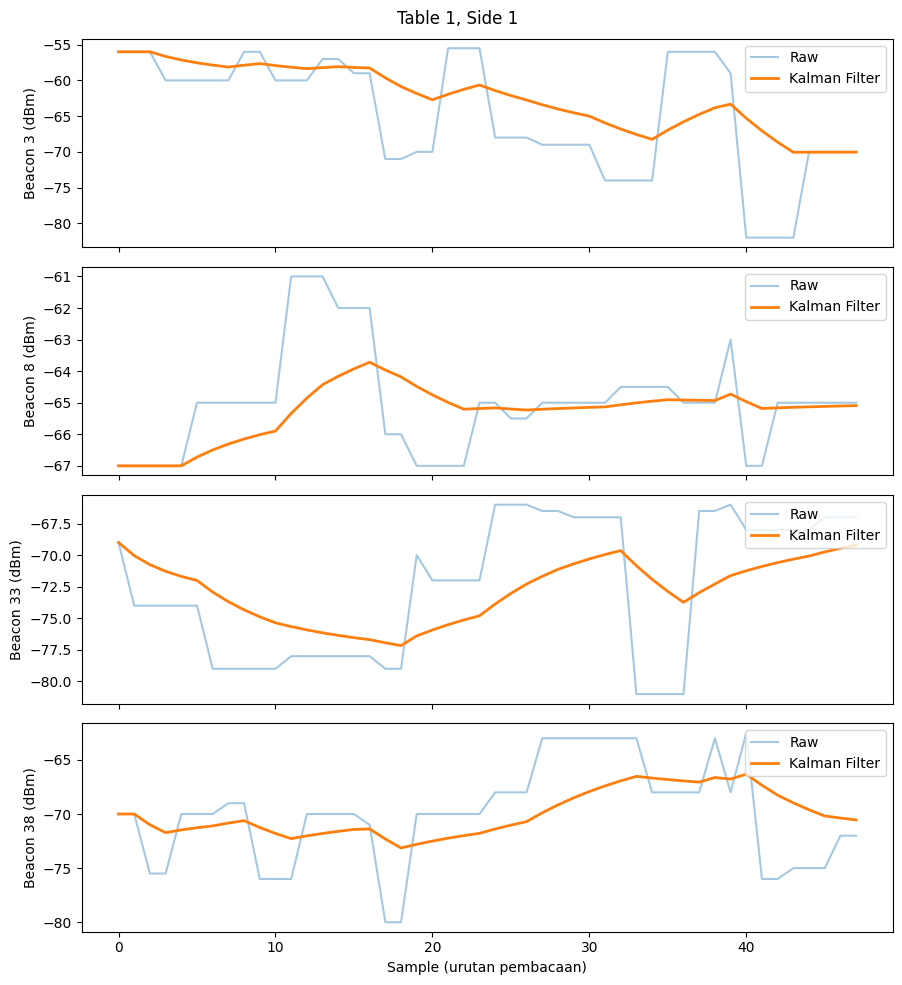

In [16]:
SAMPLE_TABLE, SAMPLE_SIDE = 1, 1

sub = df[(df['Table'] == SAMPLE_TABLE) & (df['Side'] == SAMPLE_SIDE)]

fig, axes = plt.subplots(len(BEACONS), 1, figsize=(9, 10), sharex=True)
for ax, b, col, kf_col in zip(axes, BEACONS, beacon_cols, kf_cols):
    ax.plot(sub['Sample'], sub[col], alpha=0.4, label='Raw')
    ax.plot(sub['Sample'], sub[kf_col], linewidth=2, label='Kalman Filter')
    ax.set_ylabel(f'Beacon {b} (dBm)')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Sample (urutan pembacaan)')
fig.suptitle(f'Table {SAMPLE_TABLE}, Side {SAMPLE_SIDE}')
plt.tight_layout()
plt.show()

## Feature 2 — Beacon RSSI Reranking

Urutkan ke-4 beacon per baris dari sinyal terkuat (RSSI paling besar/mendekati 0) sampai terlemah, dihitung dari nilai **hasil Kalman Filter** (bukan raw). `Rank_3 = 1` artinya beacon 3 adalah sinyal terkuat di baris itu.

In [17]:
rank_cols = [f'Rank_{b}' for b in BEACONS]
df[rank_cols] = df[kf_cols].rank(axis=1, ascending=False, method='min').astype(int)

df[[*kf_cols, *rank_cols]].head(10)

,RSSI_3_KF,RSSI_8_KF,RSSI_33_KF,RSSI_38_KF,Rank_3,Rank_8,Rank_33,Rank_38
0,-56.000000,-67.000000,-69.000000,-70.000000,1,2,3,4
1,-56.000000,-67.000000,-70.039604,-70.000000,1,2,4,3
2,-56.000000,-67.000000,-70.754893,-70.993358,1,2,3,4
3,-56.647419,-67.000000,-71.280129,-71.722779,1,2,3,4
4,-57.145171,-67.000000,-71.683944,-71.467000,1,2,4,3
5,-57.540994,-66.722700,-72.005065,-71.263601,1,2,4,3
6,-57.863870,-66.496503,-72.923526,-71.097685,1,2,4,3
7,-58.132433,-66.308357,-73.687485,-70.833956,1,2,4,3
8,-57.873474,-66.149472,-74.332628,-70.611243,1,2,4,3
9,-57.652183,-66.013699,-74.883928,-71.247751,1,2,4,3


## Feature 3 — Pairwise Difference RSSI (Adaptasi LANDMARC)

Hitung selisih RSSI (hasil Kalman Filter) untuk tiap pasangan beacon — 4 beacon menghasilkan $\binom{4}{2} = 6$ pasangan. Fitur relatif ini kebal terhadap pergeseran RSSI absolut akibat perbedaan perangkat/lingkungan, karena yang dipakai adalah *hubungan antar sinyal*, bukan nilai mutlaknya.

In [18]:
pair_cols = []
for a, b in combinations(BEACONS, 2):
    col = f'Diff_{a}_{b}'
    df[col] = df[f'RSSI_{a}_KF'] - df[f'RSSI_{b}_KF']
    pair_cols.append(col)

df[pair_cols].head(10)

,Diff_3_8,Diff_3_33,Diff_3_38,Diff_8_33,Diff_8_38,Diff_33_38
0,11.000000,13.000000,14.000000,2.000000,3.000000,1.000000
1,11.000000,14.039604,14.000000,3.039604,3.000000,-0.039604
2,11.000000,14.754893,14.993358,3.754893,3.993358,0.238465
3,10.352581,14.632710,15.075360,4.280129,4.722779,0.442650
4,9.854829,14.538773,14.321829,4.683944,4.467000,-0.216943
5,9.181706,14.464072,13.722607,5.282366,4.540901,-0.741465
6,8.632633,15.059655,13.233815,6.427023,4.601182,-1.825840
7,8.175924,15.555051,12.701523,7.379128,4.525599,-2.853529
8,8.275998,16.459154,12.737769,8.183156,4.461771,-3.721384
9,8.361516,17.231744,13.595568,8.870229,5.234053,-3.636176


## Feature Normalization / Scaling

Fitur akhir = RSSI hasil Kalman Filter + Rank + Pairwise Difference. Distandardisasi dengan `StandardScaler` (mean=0, std=1) — dibutuhkan terutama untuk **WKNN** (berbasis jarak); untuk **Random Forest** scaling tidak wajib tapi tidak masalah tetap dipakai.

Kolom RSSI mentah, hasil KF/Rank/Pairwise Diff yang belum di-scale, dan kolom sementara lain **tidak disimpan** ke CSV final — cuma dipakai selama proses di notebook ini. CSV final cuma berisi label (`Table`, `Side`, `Sample`) + fitur yang sudah dinormalisasi, siap langsung dipakai training di Phase 4.

> **Catatan penting untuk Phase 4**: `scaler.fit_transform()` di sini di-fit ke SELURUH data (global) untuk keperluan eksplorasi. Begitu masuk ke train/test split, `scaler` harus di-**fit ulang hanya pada data train**, lalu `transform` ke data test — supaya tidak terjadi *data leakage*.

In [19]:
feature_cols = kf_cols + rank_cols + pair_cols

scaler = StandardScaler()
df[feature_cols] = scaler.fit_transform(df[feature_cols])  # overwrite langsung dengan versi scaled

df_final = df[['Table', 'Side', 'Sample', *feature_cols]]

print(df_final.shape)
df_final.head()

(16346, 17)


,Table,Side,Sample,RSSI_3_KF,RSSI_8_KF,RSSI_33_KF,RSSI_38_KF,Rank_3,Rank_8,Rank_33,Rank_38,Diff_3_8,Diff_3_33,Diff_3_38,Diff_8_33,Diff_8_38,Diff_33_38
0,1,1,0,2.564398,0.524286,-0.491488,-0.656304,-1.941375,-0.89819,0.819033,2.090728,1.364359,1.903716,1.926092,0.622814,0.854482,0.108023
1,1,1,1,2.564398,0.524286,-0.631762,-0.656304,-1.941375,-0.89819,1.752248,1.053014,1.364359,2.014701,1.926092,0.716513,0.854482,0.012434
2,1,1,2,2.564398,0.524286,-0.728276,-0.791637,-1.941375,-0.89819,0.819033,2.090728,1.364359,2.091064,2.026755,0.780983,0.959467,0.038001
3,1,1,3,2.447394,0.524286,-0.799147,-0.891011,-1.941375,-0.89819,0.819033,2.090728,1.283484,2.078020,2.035065,0.828322,1.036558,0.056776
4,1,1,4,2.357439,0.524286,-0.853634,-0.856164,-1.941375,-0.89819,1.752248,1.053014,1.221306,2.067991,1.958705,0.864718,1.009525,-0.003872


## Simpan Hasil

Simpan dataset fitur (`df_final`) dan `scaler` (untuk dipakai ulang / referensi di Phase 4) langsung ke local directory.

In [20]:
import joblib

output_name = 'ips_dataset_features_v1.csv'
scaler_name = 'ips_scaler_v1.joblib'

df_final.to_csv(output_name, index=False)          # working dir sudah di PROJECT_PATH -> otomatis ke Main_Data
joblib.dump(scaler, scaler_name)

print(f"Tersimpan ke: {os.path.join(PROJECT_PATH, output_name)}")
print(f"Scaler tersimpan: {os.path.join(PROJECT_PATH, scaler_name)}")
print(f"({df_final.shape[0]} baris x {df_final.shape[1]} kolom)")


Tersimpan ke Google Drive: /content/drive/MyDrive/Penting/Research/QOS Position - Bluetooth and Wifi for Smart Class Absence based on Chair/Code/Dataset/ips_dataset_features_v1.csv
Scaler tersimpan: /content/drive/MyDrive/Penting/Research/QOS Position - Bluetooth and Wifi for Smart Class Absence based on Chair/Code/Dataset/ips_scaler_v1.joblib
(16346 baris x 17 kolom)
